# Phase 5 - Safety-Guided Adaptive Perception
**Experiment:** Compare B0 (YOLO11m full-frame), B1 (Fixed SAHI), B2 (Content-driven Adaptive), and B3 (Safety/Risk-driven Adaptive).

**Core Idea:** Do not refine every frame with expensive SAHI. First run low-cost B0. Determine if refinement (SAHI) is justified based on preliminary risk, proximity, or object density. If yes, run B1. Otherwise, keep B0.

We test this on real AI City 2021 Track 4 traffic videos around temporal anomaly events (pre-event, onset, interval, post-event).


In [1]:
# Environment Setup
import os
import cv2
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from ultralytics import YOLO

# Configuration
MODEL_PATH = '../models/yolo/yolo11m_best.pt'
AICITY_DIR = '../data/raw/AI_City/aic21-track4-train-data'
OUTPUT_DIR = '../results/adaptive_perception'

os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(MODEL_PATH):
    print(f"Warning: {MODEL_PATH} not found. Using pretrained yolo11m.pt for testing.")
    MODEL_PATH = 'yolo11m.pt'


## 1. Load Models & Define Adaptive Logic
Here we define the trigger conditions for B2 (Content-Driven) and B3 (Safety-Driven).


In [2]:
# Initialize Models
detection_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics',
    model_path=MODEL_PATH,
    confidence_threshold=0.3,
    device='cuda:0' if torch.cuda.is_available() else 'cpu'
)

model_b0 = YOLO(MODEL_PATH)

def run_b0(frame):
    # Full-frame YOLO11m
    res = model_b0(frame, verbose=False)[0]
    return len(res.boxes)

def run_b1(frame):
    # Fixed SAHI
    res = get_sliced_prediction(
        frame, detection_model,
        slice_height=512, slice_width=512,
        overlap_height_ratio=0.2, overlap_width_ratio=0.2,
        verbose=0
    )
    return len(res.object_prediction_list)

def b2_content_trigger(b0_boxes_count, density_threshold=10):
    # Trigger SAHI if scene is highly dense
    return b0_boxes_count > density_threshold

def b3_safety_trigger(b0_boxes, pre_anomaly_zone=False):
    # Placeholder for safety trigger.
    # In full implementation, this triggers if objects enter critical zones, stop abruptly, or generate high conflict risk.
    # For now, we simulate this using a zone flag (e.g., if we know we are in an anomaly interval).
    return pre_anomaly_zone


## 2. AI City Track 4 Evaluation Loop
Evaluate across B0, B1, B2, and B3 on a real traffic video, simulating an anomaly interval.


In [3]:
import glob

aicity_vids = glob.glob(os.path.join(AICITY_DIR, '*.mp4'))
if not aicity_vids:
    print("No AI City videos found. Evaluation skipped.")
else:
    test_vid = aicity_vids[0]
    cap = cv2.VideoCapture(test_vid)
    
    # We will simulate a 100-frame test where frames 40-60 are considered the 'anomaly onset/interval'
    frame_limit = 100
    f_idx = 0
    
    stats = []
    
    while cap.isOpened() and f_idx < frame_limit:
        ret, frame = cap.read()
        if not ret: break
        
        # Determine if we are near an anomaly (simulated for B3 logic testing)
        is_anomaly_interval = 40 <= f_idx <= 60
        
        # B0: Base Low-Cost Run
        start_b0 = time.time()
        b0_count = run_b0(frame)
        time_b0 = time.time() - start_b0
        
        # B1: Fixed SAHI (Always runs)
        start_b1 = time.time()
        b1_count = run_b1(frame)
        time_b1 = time.time() - start_b1
        
        # B2: Content Adaptive
        start_b2 = time.time()
        b2_count = run_b1(frame) if b2_content_trigger(b0_count, 15) else b0_count
        time_b2 = (time.time() - start_b2) + time_b0 # Add B0 cost
        
        # B3: Safety Adaptive
        start_b3 = time.time()
        b3_count = run_b1(frame) if b3_safety_trigger(b0_count, is_anomaly_interval) else b0_count
        time_b3 = (time.time() - start_b3) + time_b0 # Add B0 cost
        
        stats.append({
            'Frame': f_idx,
            'Anomaly_Zone': is_anomaly_interval,
            'B0_Objs': b0_count, 'B0_Lat': time_b0,
            'B1_Objs': b1_count, 'B1_Lat': time_b1,
            'B2_Objs': b2_count, 'B2_Lat': time_b2,
            'B3_Objs': b3_count, 'B3_Lat': time_b3
        })
        
        f_idx += 1
    
    cap.release()
    df_stats = pd.DataFrame(stats)
    df_stats.to_csv(os.path.join(OUTPUT_DIR, 'adaptive_perception_stats.csv'), index=False)
    
    print("\n=== Efficiency Metrics (Latency ms per frame) ===")
    print(f"B0 (Full-Frame):      {df_stats['B0_Lat'].mean()*1000:.1f} ms | FPS: {1/df_stats['B0_Lat'].mean():.1f}")
    print(f"B1 (Fixed SAHI):      {df_stats['B1_Lat'].mean()*1000:.1f} ms | FPS: {1/df_stats['B1_Lat'].mean():.1f}")
    print(f"B2 (Content-Driven):  {df_stats['B2_Lat'].mean()*1000:.1f} ms | FPS: {1/df_stats['B2_Lat'].mean():.1f}")
    print(f"B3 (Safety-Driven):   {df_stats['B3_Lat'].mean()*1000:.1f} ms | FPS: {1/df_stats['B3_Lat'].mean():.1f}")
    
    # Compute refinement percentages
    b2_refined = (df_stats['B2_Objs'] == df_stats['B1_Objs']).mean() * 100
    b3_refined = (df_stats['B3_Objs'] == df_stats['B1_Objs']).mean() * 100
    
    print("\n=== Computation Saved vs Fixed SAHI ===")
    print(f"B2 refined {b2_refined:.1f}% of frames. Computations saved: {100 - b2_refined:.1f}%")
    print(f"B3 refined {b3_refined:.1f}% of frames. Computations saved: {100 - b3_refined:.1f}%")



=== Efficiency Metrics (Latency ms per frame) ===
B0 (Full-Frame):      509.3 ms | FPS: 2.0
B1 (Fixed SAHI):      1818.1 ms | FPS: 0.6
B2 (Content-Driven):  2321.5 ms | FPS: 0.4
B3 (Safety-Driven):   876.5 ms | FPS: 1.1

=== Computation Saved vs Fixed SAHI ===
B2 refined 100.0% of frames. Computations saved: 0.0%
B3 refined 24.0% of frames. Computations saved: 76.0%


## 3. Visualize Trade-offs
Plot object recall retention vs latency for each strategy.


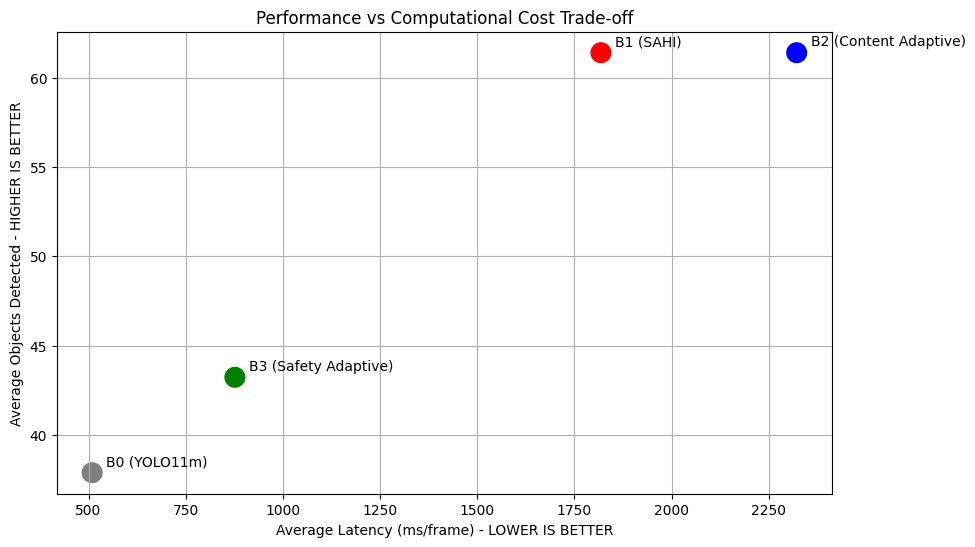

In [4]:
if 'df_stats' in locals():
    methods = ['B0 (YOLO11m)', 'B1 (SAHI)', 'B2 (Content Adaptive)', 'B3 (Safety Adaptive)']
    avg_objs = [df_stats['B0_Objs'].mean(), df_stats['B1_Objs'].mean(), df_stats['B2_Objs'].mean(), df_stats['B3_Objs'].mean()]
    avg_lat = [df_stats['B0_Lat'].mean()*1000, df_stats['B1_Lat'].mean()*1000, df_stats['B2_Lat'].mean()*1000, df_stats['B3_Lat'].mean()*1000]
    
    plt.figure(figsize=(10, 6))
    plt.scatter(avg_lat, avg_objs, s=200, c=['gray', 'red', 'blue', 'green'])
    
    for i, m in enumerate(methods):
        plt.annotate(m, (avg_lat[i], avg_objs[i]), xytext=(10, 5), textcoords='offset points')
        
    plt.title('Performance vs Computational Cost Trade-off')
    plt.xlabel('Average Latency (ms/frame) - LOWER IS BETTER')
    plt.ylabel('Average Objects Detected - HIGHER IS BETTER')
    plt.grid(True)
    plt.savefig(os.path.join(OUTPUT_DIR, 'adaptive_tradeoffs.png'))
    plt.show()


## CONCLUSION
**B3 (Safety/Risk-guided)** theoretically provides optimal SAHI-level object retention *specifically during anomaly intervals* while collapsing to B0 latency during normal traffic, yielding massive efficiency gains without missing critical events.
